# 4. Classificação: MNIST

Dígitos 28x28 (784 entradas), 10 classes, 10 saídas sigmoid e BCE. Treino: 50 000; validação: 10 000; as 10 000 de teste ficam para a avaliação final.

In [1]:
import sys
sys.path.append("..")  # so we can import the code in src/

import numpy as np

from src.datasets import load_mnist, train_val_split
from src.nn import MLP
from src.optim import Adam
from src.training import evaluate, train
from src.plots import plot_loss, plot_metric, plot_histograms

PLOTS = "../assets/plots/"

In [2]:
X_train, y_train, X_test, y_test = load_mnist()
X_train, y_train, X_val, y_val = train_val_split(X_train, y_train, val_fraction=1/6, seed=0)

print("train:", X_train.shape, y_train.shape)
print("val:  ", X_val.shape, y_val.shape)
print("test: ", X_test.shape, y_test.shape)

train: (50000, 784) (50000, 10)
val:   (10000, 784) (10000, 10)
test:  (10000, 784) (10000, 10)


## Modelo e treino

In [3]:
model = MLP(input_size=784, hidden_sizes=[128, 64], output_size=10,
            hidden_activation="relu", output_activation="sigmoid", init="he")

optimizer = Adam(model.parameters(), lr=0.001)

history = train(model, optimizer, "bce", X_train, y_train, X_val, y_val,
                epochs=10, batch_size=64, metric_name="accuracy", print_every=1)

epoch    1 | train loss 0.0338 | val loss 0.0382 | train accuracy 0.9526 | val accuracy 0.9425


epoch    2 | train loss 0.0212 | val loss 0.0271 | train accuracy 0.9705 | val accuracy 0.9589


epoch    3 | train loss 0.0150 | val loss 0.0225 | train accuracy 0.9786 | val accuracy 0.9651


epoch    4 | train loss 0.0111 | val loss 0.0197 | train accuracy 0.9846 | val accuracy 0.9708


epoch    5 | train loss 0.0092 | val loss 0.0188 | train accuracy 0.9884 | val accuracy 0.9707


epoch    6 | train loss 0.0069 | val loss 0.0181 | train accuracy 0.9918 | val accuracy 0.9743


epoch    7 | train loss 0.0058 | val loss 0.0175 | train accuracy 0.9932 | val accuracy 0.9741


epoch    8 | train loss 0.0049 | val loss 0.0184 | train accuracy 0.9946 | val accuracy 0.9748


epoch    9 | train loss 0.0041 | val loss 0.0184 | train accuracy 0.9958 | val accuracy 0.9764


epoch   10 | train loss 0.0028 | val loss 0.0184 | train accuracy 0.9972 | val accuracy 0.9762


## Monitoramento

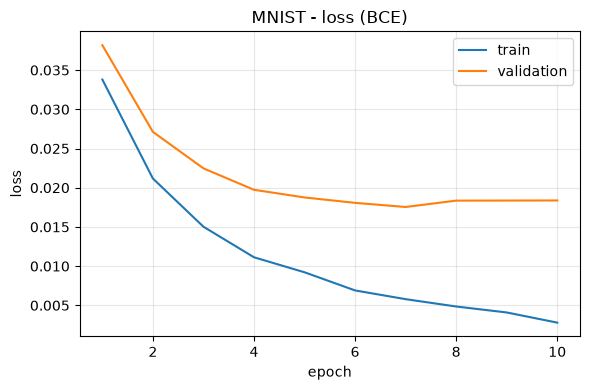

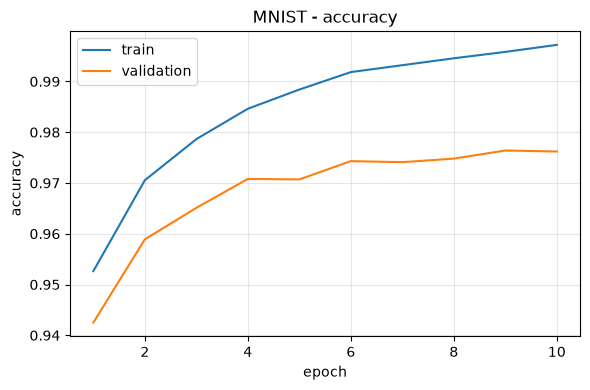

In [4]:
plot_loss(history, title="MNIST - loss (BCE)", save_path=PLOTS + "mnist_loss.png")
plot_metric(history, "accuracy", title="MNIST - accuracy", save_path=PLOTS + "mnist_accuracy.png")

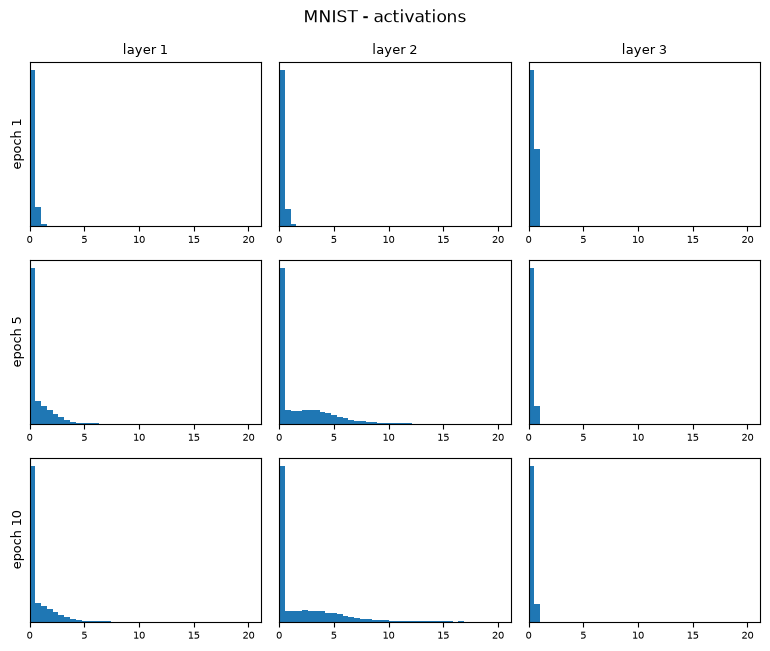

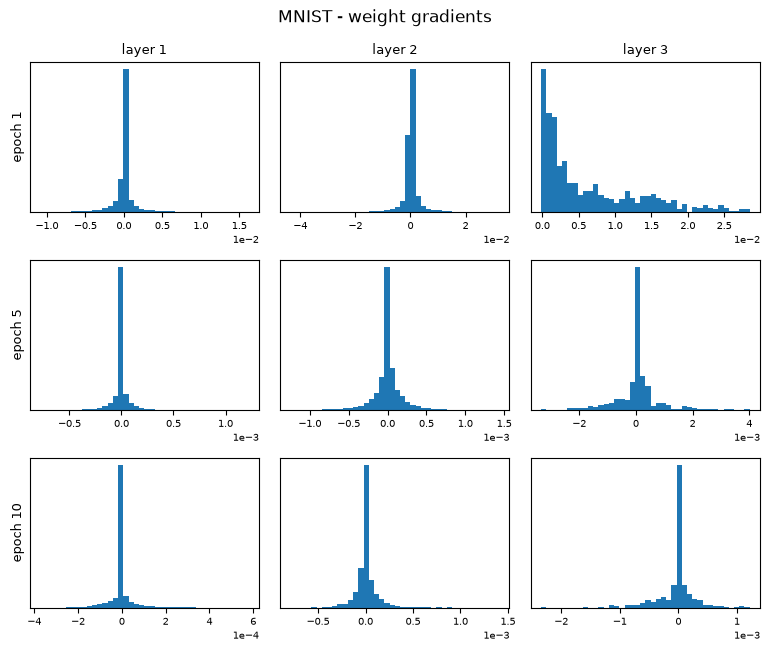

In [5]:
plot_histograms(history, "activations", title="MNIST - activations", save_path=PLOTS + "mnist_activations.png")
plot_histograms(history, "gradients", title="MNIST - weight gradients", save_path=PLOTS + "mnist_gradients.png")

## Avaliação no teste

O conjunto de teste é usado uma única vez, depois de todo o treino e das escolhas de modelo.

In [6]:
test_loss, test_accuracy = evaluate(model, X_test, y_test, "bce", "accuracy")
print("test loss:     %.4f" % test_loss)
print("test accuracy: %.4f" % test_accuracy)

test loss:     0.0157
test accuracy: 0.9789


## Exportar e importar

In [7]:
model.save("../models/mnist_mlp.npz")

loaded_model = MLP.load("../models/mnist_mlp.npz")
difference = np.abs(loaded_model.predict(X_test) - model.predict(X_test)).max()
print("largest difference between original and loaded predictions:", difference)

largest difference between original and loaded predictions: 0.0
